In [1]:
import librosa

array, sampling_rate = librosa.load(librosa.ex("trumpet"))

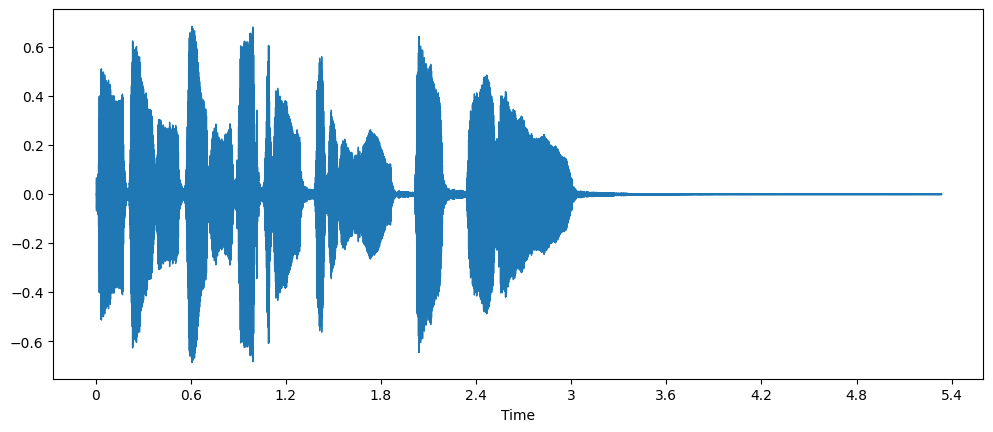

In [2]:
import matplotlib.pyplot as plt
import librosa.display

plt.figure().set_figwidth(12)
librosa.display.waveshow(array, sr=sampling_rate) # x axis = aplitude, y = time

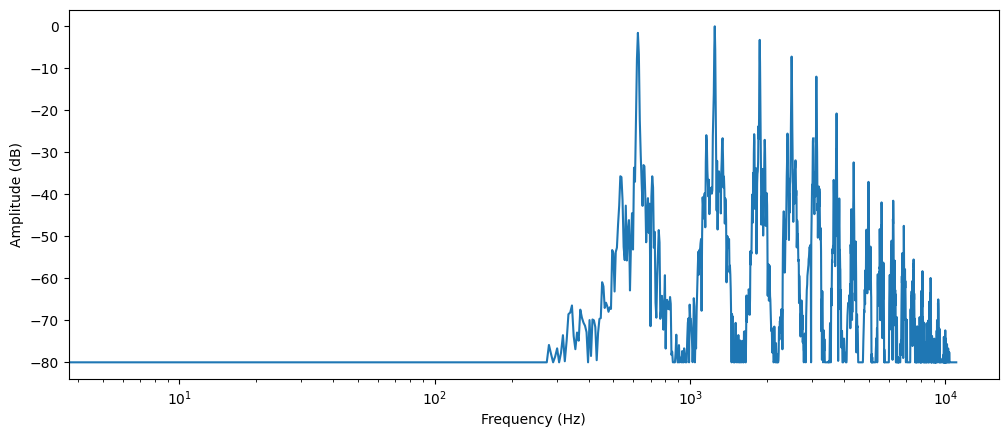

In [4]:
import numpy as np

dft_input = array[:4096]

# calculate the discrete Fourier transform (DFT)
window = np.hanning(len(dft_input))
windowed_input = dft_input * window
dft = np.fft.rfft(windowed_input)


# get the amplitude spectrum in dB
amplitude = np.abs(dft)
amplitude_db = librosa.amplitude_to_db(amplitude, ref= np.max)

#get frequency bins
frequency = librosa.fft_frequencies(sr= sampling_rate, n_fft=len(dft_input))

plt.figure().set_figwidth(12)
plt.plot(frequency, amplitude_db)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (dB)")
plt.xscale("log")



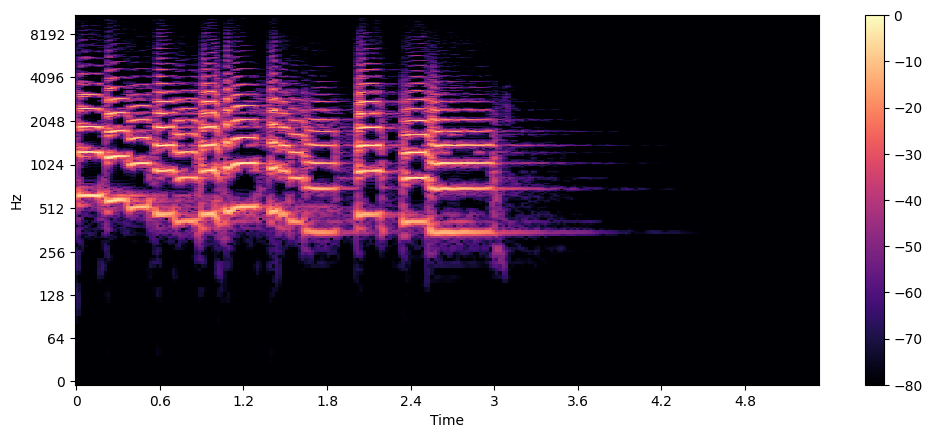

In [5]:
D = librosa.stft(array)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
# A spectrogram plots the frequency content of an audio signal  as it changes over time.
# It allows you to see time, frequency, and amplitude all on one graph.


plt.figure().set_figwidth(12)
librosa.display.specshow(S_db, x_axis='time', y_axis='log')
plt.colorbar()

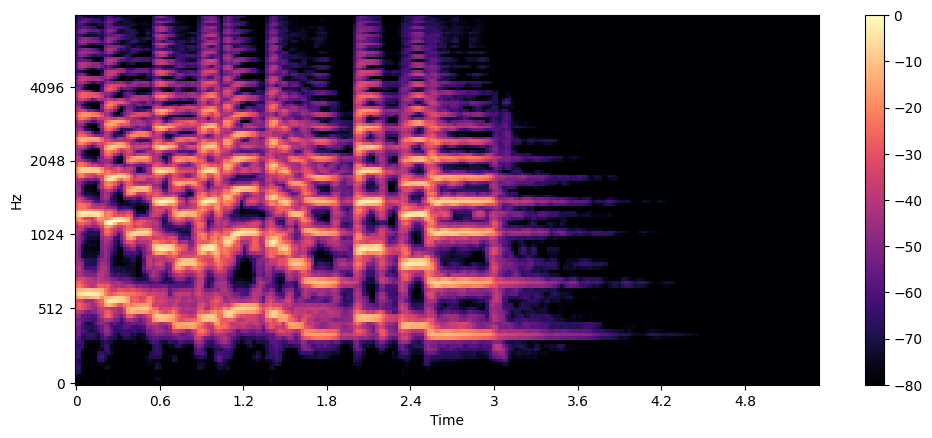

In [6]:
# Mel spectogram. It corrects the normal spectrogram using the perceptual mel scale,
# which approximates the non-linear frequency response of the human ear.
S = librosa.feature.melspectrogram(y= array, sr=sampling_rate, n_mels=120, fmax=8000)
S_db = librosa.power_to_db(S, ref=np.max)

plt.figure().set_figwidth(12)
librosa.display.specshow(S_db, x_axis="time", y_axis="mel", sr=sampling_rate, fmax=8000)
plt.colorbar()